# Process the sqY2H data

This is the main PPI profiling assay. This script loads the raw scores and processes them into consensus scores. Throughout the script, "ad" means "activation domain" and "db" means "DNA binding domain" of a transcription factor. A protein is fused to each of these; if the two proteins interact, then the TF is able to up-regulate the expression of a gene that allows the yeast to survive on the media. Thus, the yeast growth score is correlated to the protein-protein interaction strength.

In [24]:
import pandas as pd 
import polars as pl
import numpy as np
from striprtf.striprtf import rtf_to_text
import re

In [25]:
inputs_dir = "../1_inputs/sqY2H"
outputs_dir = "../3_outputs"
meta_outputs = "../../../1_allele_collection/3_outputs"
meta_inputs = "../../../1_allele_collection/1_inputs"

# Automated clean processing

Number of rows before replacing outliers: 306431
Number of values replaced with NaN: 3057
Percentage of values replaced: 1.00%
Number of rows after replacing outliers: 306431


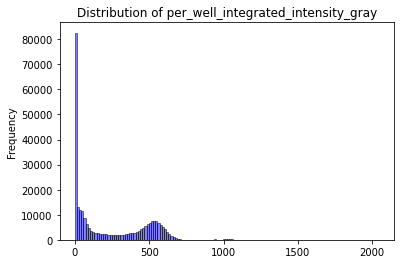

In [26]:
# Load the data from the automated scoring pipeline
auto_df = pd.read_csv(f"{inputs_dir}/sqY2H_manual_automated_annotated_scores.csv")

# both ad_orf_id and db_orf_id must have values (otherwise they are empty wells)
auto_df = auto_df[
    (~auto_df.ad_orf_id.isin(['nan', 'None'])) &
    (~auto_df.db_orf_id.isin(['nan', 'None']))
]

# Remove rows where manual_score_growth is NaN because those wells are flagged as contamination

# do not drop but replace the automatic scores by NA or just add a column for the failling of the manual annotation
# auto_df.dropna(subset=['manual_score_growth'], inplace=True)
auto_df['contamination'] = auto_df['manual_score_growth'].isna()
auto_df

# try to replace per_well_integrated_intensity_gray with NaN if manual_score_growth is NaN
auto_df.loc[auto_df['manual_score_growth'].isna(), 'per_well_integrated_intensity_gray'] = np.nan

# plotting the distribution of per_well_integrated_intensity_gray
auto_df.per_well_integrated_intensity_gray.plot(kind='hist', bins=140, alpha=0.5, color='blue', edgecolor='black', title="Distribution of per_well_integrated_intensity_gray")

# replacing upper bound outliers with NaN because they're caused by misaligned wells
auto_full = auto_df.copy()

# Counting the number of values replaced with NaN
outlier_mask = auto_df.per_well_integrated_intensity_gray >= 750
num_outliers = outlier_mask.sum()

print(f"Number of rows before replacing outliers: {len(auto_df)}")
auto_df.loc[outlier_mask, 'per_well_integrated_intensity_gray'] = np.nan
print(f"Number of values replaced with NaN: {num_outliers}")
print(f"Percentage of values replaced: {(num_outliers / len(auto_df)) * 100:.2f}%")
print(f"Number of rows after replacing outliers: {len(auto_df)}")

<Axes: title={'center': 'Distribution of per_well_integrated_intensity_gray'}, ylabel='Frequency'>

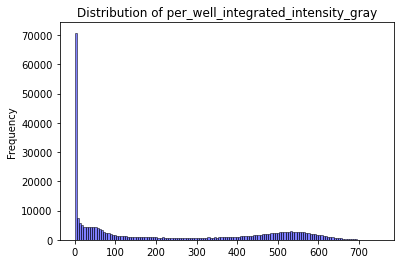

In [27]:
auto_df.per_well_integrated_intensity_gray.plot(kind='hist', bins=140, alpha=0.5, color='blue', edgecolor='black', title="Distribution of per_well_integrated_intensity_gray")


In [28]:
auto_df['automated_log2'] = np.log2(auto_df['per_well_integrated_intensity_gray'] + 50)  # Adding 1 to avoid log(0)

<Axes: title={'center': 'Distribution of log2(per_well_integrated_intensity_gray + 1)'}, ylabel='Frequency'>

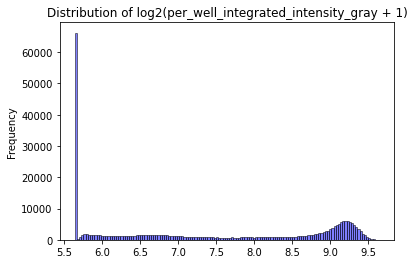

In [29]:
auto_df.automated_log2.plot(kind='hist', bins=140, alpha=0.5, color='blue', edgecolor='black', title="Distribution of log2(per_well_integrated_intensity_gray + 1)")

In [30]:
# get media control thresholds
media_score_thresholds = pd.read_csv(f"{inputs_dir}/media_control_score_thresholds.csv")
media_score_thresholds.rename(columns={'control_96': 'scoring_pos'}, inplace=True)

# Split into media controls
media_ctrls = auto_df[auto_df['media_control'] == True]
# auto_df = auto_df[~auto_df['media_control']]

# Check media controls
media_ctrls = media_ctrls[['db_orf_id', 'condition_name', 'retest_batch', 'per_well_integrated_intensity_gray']]
media_ctrls[['scoring_pos', 'retest_pla']] = media_ctrls['db_orf_id'].str.split('_', n=1, expand=True)
media_ctrls = media_ctrls.merge(media_score_thresholds, on=['scoring_pos', 'condition_name'])
media_ctrls

,db_orf_id,condition_name,retest_batch,per_well_integrated_intensity_gray,scoring_pos,retest_pla,control_384,lower_bound,upper_bound
0,A01_1,LW,VUSAPWT1B1,490.572572,A01,1,A01_A02_B01_B02,4,4
1,A01_1,LW,VUSAPWT1B1,521.929437,A01,1,A01_A02_B01_B02,4,4
2,A01_1,LW,VUSAPWT1B1,549.292837,A01,1,A01_A02_B01_B02,4,4
3,A01_1,LW,VUSAPWT1B1,477.786949,A01,1,A01_A02_B01_B02,4,4
4,B01_1,LW,VUSAPWT1B1,465.789564,B01,1,C01_C02_D01_D02,4,4
...,...,...,...,...,...,...,...,...,...
2392,E01_31,LWH25,VUSAPWT1B1,528.958176,E01,31,I01_I02_J01_J02,3,4
2393,F01_31,LWH25,VUSAPWT1B1,473.044449,F01,31,K01_K02_L01_L02,1,3
2394,F01_31,LWH25,VUSAPWT1B1,223.918957,F01,31,K01_K02_L01_L02,1,3
2395,F01_31,LWH25,VUSAPWT1B1,488.665364,F01,31,K01_K02_L01_L02,1,3


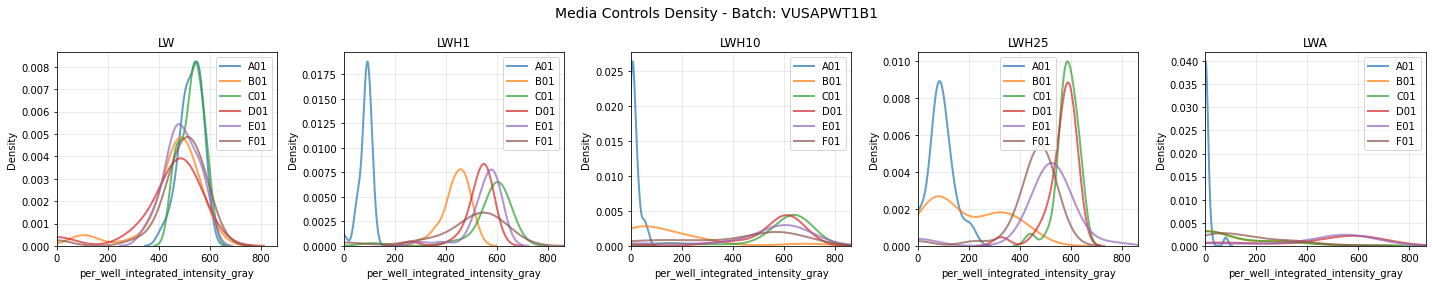

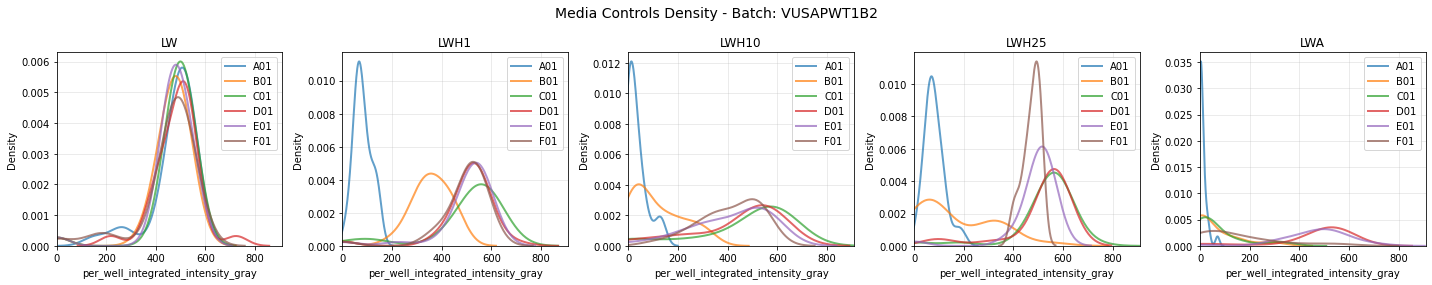

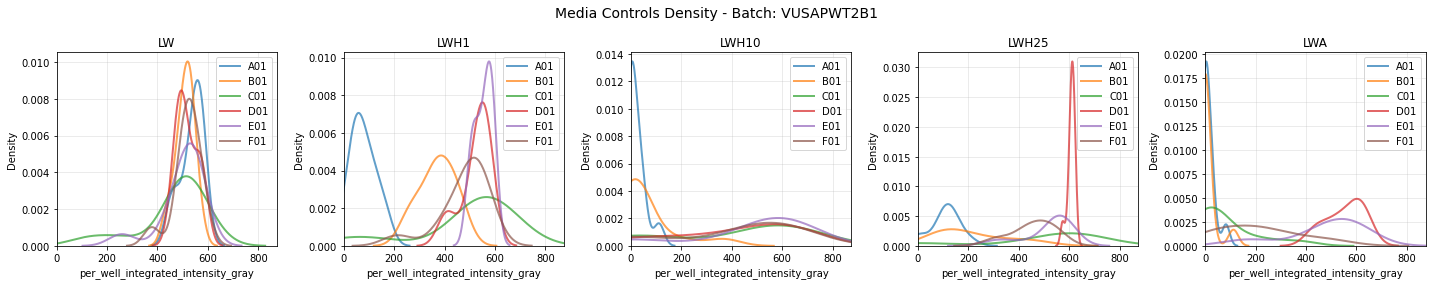

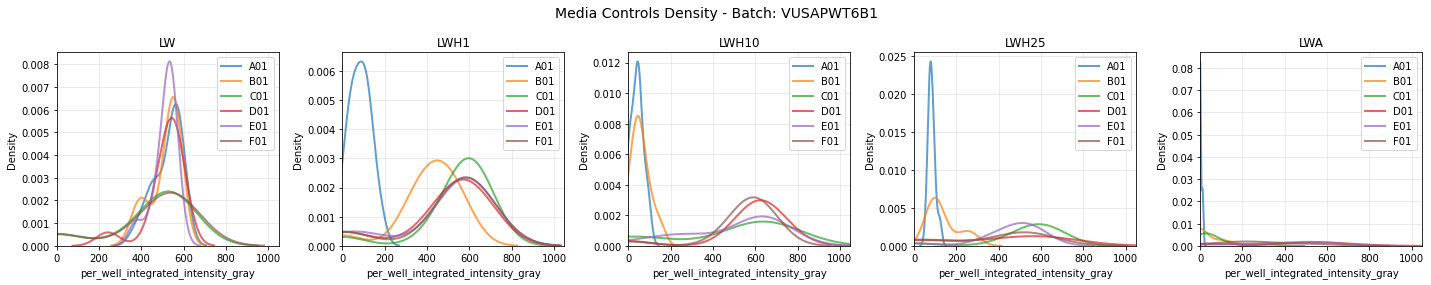

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Get unique retest_batches and condition_names
retest_batches = media_ctrls['retest_batch'].unique()
condition_names = media_ctrls['condition_name'].unique()
condition_names = ['LW', 'LWH1', 'LWH10', 'LWH25', 'LWA']

for batch in retest_batches:
    # Filter data for this batch
    batch_data = media_ctrls[media_ctrls['retest_batch'] == batch]
    
    # Create subplots - one for each condition
    n_conditions = len(condition_names)
    fig, axes = plt.subplots(1, n_conditions, figsize=(4*n_conditions, 4), sharex=True)
    
    # Handle case where there's only one condition
    if n_conditions == 1:
        axes = [axes]
    
    fig.suptitle(f'Media Controls Density - Batch: {batch}', fontsize=14)
    
    for i, condition in enumerate(condition_names):
        ax = axes[i]
        condition_data = batch_data[batch_data['condition_name'] == condition]
        
        if len(condition_data) > 0:
            # Get unique scoring_pos for this condition
            scoring_positions = condition_data['scoring_pos'].unique()
            
            for pos in scoring_positions:
                pos_data = condition_data[condition_data['scoring_pos'] == pos]
                values = pos_data['per_well_integrated_intensity_gray'].values
                
                if len(values) > 0:
                    # Create density curve using seaborn kdeplot
                    sns.kdeplot(x=values, label=f'{pos}', alpha=0.7, linewidth=2, ax=ax)
        
        ax.set_title(f'{condition}')
        ax.set_xlabel('per_well_integrated_intensity_gray')
        ax.set_ylabel('Density')
        ax.set_xlim(left=0)  # Set lower bound of x-axis to 0
        ax.legend()
        ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages

# Get unique retest_batches and condition_names
retest_batches = media_ctrls['retest_batch'].unique()
condition_names = ['LW', 'LWH1', 'LWH10', 'LWH25', 'LWA']

# Create a single figure with subplots for all batches and conditions
n_batches = len(retest_batches)
n_conditions = len(condition_names)

# Create PDF file
with PdfPages(f'{outputs_dir}/sqY2H/media_controls_density_plots.pdf') as pdf:
    fig, axes = plt.subplots(n_batches, n_conditions, figsize=(5*n_conditions, 4*n_batches), sharex=True)#, sharey=True)
    
    # Handle case where there's only one batch
    if n_batches == 1:
        axes = axes.reshape(1, -1)
    # Handle case where there's only one condition
    if n_conditions == 1:
        axes = axes.reshape(-1, 1)
    
    fig.suptitle('Media Controls Density Plots - All Batches', fontsize=16)
    
    for batch_idx, batch in enumerate(retest_batches):
        # Filter data for this batch
        batch_data = media_ctrls[media_ctrls['retest_batch'] == batch]
        
        for condition_idx, condition in enumerate(condition_names):
            ax = axes[batch_idx, condition_idx]
            condition_data = batch_data[batch_data['condition_name'] == condition]
            
            if len(condition_data) > 0:
                # Get unique scoring_pos for this condition
                scoring_positions = condition_data['scoring_pos'].unique()
                
                for pos in scoring_positions:
                    pos_data = condition_data[condition_data['scoring_pos'] == pos]
                    values = pos_data['per_well_integrated_intensity_gray'].values
                    
                    if len(values) > 0:
                        # Create density curve using seaborn kdeplot
                        sns.kdeplot(x=values, label=f'{pos}', alpha=0.7, linewidth=2, ax=ax)
            
            # Set titles and labels
            if batch_idx == 0:
                ax.set_title(f'{condition}', fontsize=12)
            if condition_idx == 0:
                ax.set_ylabel(f'Batch {batch}\nDensity', fontsize=10)
            if batch_idx == n_batches - 1:
                ax.set_xlabel('per_well_integrated_intensity_gray', fontsize=10)
            
            ax.set_xlim(left=0)
            ax.legend(fontsize=8)
            ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    pdf.savefig(fig, bbox_inches='tight')
    plt.close()

print("PDF saved as 'media_controls_density_plots.pdf'")

PDF saved as 'media_controls_density_plots.pdf'


/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


95th percentile of MADs: 179.3738266281783


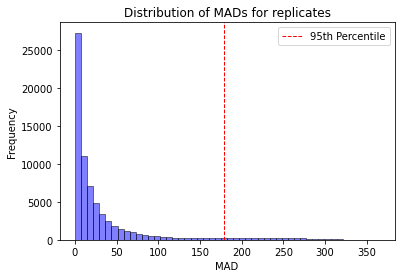

Number of replicates with MAD below 95th percentile: 66674
Total number of replicates: 71706


In [33]:
mads = []

mads_tuples = []

for group, df in auto_df.groupby(['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']):
    scores = df['per_well_integrated_intensity_gray'].dropna().values
    scores_nan = df['per_well_integrated_intensity_gray'].values
    # compute the Median absolute deviation (MAD) of the scores
    median = np.median(scores)
    mean = np.mean(scores)
    mad = np.median(np.abs(scores - median))
    mads.append(mad)
    mads_tuples.append((mad, scores, median, mean))
    # if np.isnan(mad):
        # print(f"Group {group} has NaN MAD with scores: {scores_nan}")

# 95th percentile of MADs, dropping NaNs first
mads_no_nan = [mad for mad in mads if not np.isnan(mad)]
mad_95 = np.percentile(mads_no_nan, 95)
print(f"95th percentile of MADs: {mad_95}")

plt.hist(mads, bins=50, alpha=0.5, color='blue', edgecolor='black')
plt.axvline(mad_95, color='red', linestyle='dashed', linewidth=1, label='95th Percentile')
plt.xlabel('MAD')
plt.ylabel('Frequency')
plt.title('Distribution of MADs for replicates')
plt.legend()
plt.show()

# count the number of replicates with MAD below the 95th percentile
num_below_95 = sum(mad < mad_95 for mad in mads)
print(f"Number of replicates with MAD below 95th percentile: {num_below_95}")
print(f"Total number of replicates: {len(mads)}")


In [34]:
# sorted_mads_tuples = sorted(
#     [x for x in mads_tuples if not np.isnan(x[0])],
#     key=lambda x: x[0],
#     reverse=True
# )
# for mad, scores, median, mean in sorted_mads_tuples:
#     print(scores)
#     print(f"MAD: {mad}, Median: {median}, Mean: {mean}")
#     print()

/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


95th percentile of mads_log2: 1.1826697233677714


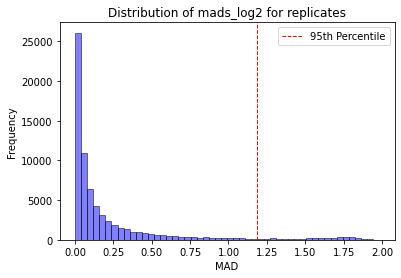

Number of replicates with MAD below 95th percentile: 66674
Total number of replicates: 71706


In [35]:
mads_log2 = []

mads_tuples_log2 = []

for group, df in auto_df.groupby(['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']):
    scores = df['automated_log2'].dropna().values
    scores_nan = df['automated_log2'].values
    # compute the Median absolute deviation (MAD) of the scores
    median = np.median(scores)
    mean = np.mean(scores)
    mad = np.median(np.abs(scores - median))
    mads_log2.append(mad)
    
    scores_nolog = df['per_well_integrated_intensity_gray'].dropna().values
    scores_nan_nolog = df['per_well_integrated_intensity_gray'].values
    # compute the Median absolute deviation (MAD) of the scores
    median_nolog = np.median(scores_nolog)
    mean_nolog = np.mean(scores_nolog)
    mad_nolog = np.median(np.abs(scores_nolog - median_nolog))
    # mads.append(mad)
    no_log_tuple = (mad_nolog, scores_nolog, median_nolog, mean_nolog)
    mads_tuples_log2.append((mad, scores, median, mean, no_log_tuple))
    
    # mads_tuples.append((mad, scores, median, mean))
    # mads
    # if np.isnan(mad):
        # print(f"Group {group} has NaN MAD with scores: {scores_nan}")

# 95th percentile of MADs, dropping NaNs first
mads_log2_no_nan = [mad for mad in mads_log2 if not np.isnan(mad)]
mad_95_log2 = np.percentile(mads_log2_no_nan, 95)
print(f"95th percentile of mads_log2: {mad_95_log2}")

plt.hist(mads_log2, bins=50, alpha=0.5, color='blue', edgecolor='black')
plt.axvline(mad_95_log2, color='red', linestyle='dashed', linewidth=1, label='95th Percentile')
plt.xlabel('MAD')
plt.ylabel('Frequency')
plt.title('Distribution of mads_log2 for replicates')
plt.legend()
plt.show()

# count the number of replicates with MAD below the 95th percentile
num_below_95 = sum(mad < mad_95_log2 for mad in mads_log2)
print(f"Number of replicates with MAD below 95th percentile: {num_below_95}")
print(f"Total number of replicates: {len(mads_log2)}")


In [36]:
# sorted_mads_tuples_log2 = sorted(
#     [x for x in mads_tuples_log2 if not np.isnan(x[0])],
#     key=lambda x: x[0],
#     reverse=True
# )
# for mad, scores, median, mean, nolog_tuple in sorted_mads_tuples_log2:
#     print(scores)
#     print(f"MAD: {mad}, Median: {median}, Mean: {mean}\nNo Log Tuple: {nolog_tuple}")
#     print()

In [37]:
# mads

Number of groups with consensus score: 66018
Number of groups without consensus score: 5688
Total number of groups: 71706
Percentage of groups with consensus score: 92.07%


<Axes: ylabel='Frequency'>

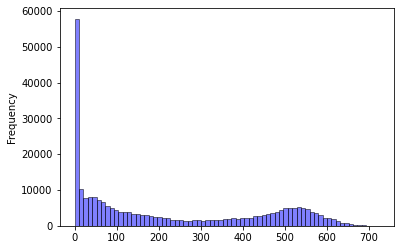

In [38]:
# Compute consensus scores for replicates with MAD below the 95th percentile by taking the mean of the scores and adding it to a new column 'consensus_score'
auto_df['consensus_score'] = np.nan
auto_df['consensus_score'] = auto_df.groupby(
    ['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']
)['per_well_integrated_intensity_gray'].transform(
    lambda x: np.mean(x.dropna()) if len(x.dropna()) > 2 and np.median(np.abs(x.dropna() - np.median(x.dropna()))) < mad_95 else np.nan
)

# Count groups with and without consensus scores more efficiently
consensus_summary = auto_df.groupby(['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch'])['consensus_score'].first().notna()
consensus_count = consensus_summary.sum()
no_consensus_count = len(consensus_summary) - consensus_count

print(f"Number of groups with consensus score: {consensus_count}")
print(f"Number of groups without consensus score: {no_consensus_count}")
print(f"Total number of groups: {len(consensus_summary)}")
print(f"Percentage of groups with consensus score: {consensus_count / len(consensus_summary) * 100:.2f}%")
auto_df['consensus_score'].plot(kind='hist', bins=70, alpha=0.5, color='blue', edgecolor='black')

In [39]:
# for group, df in auto_df.groupby(['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']):
#     print('Replicates', df.per_well_integrated_intensity_gray.values)
#     print('Consensus score', df.consensus_score.values[0])
#     print('---')

In [40]:
# map ad_orf_id to ad_symbol

mapping_file = pd.read_csv(f"{inputs_dir}/cp_files/mapping_y2h.csv")
mapping_file.dropna(subset=['ad_orf_id'], inplace=True)
mapping_dict = mapping_file.set_index('ad_orf_id')['ad_symbol'].to_dict()

# Convert to polars for mapping
auto_df_pl = pl.DataFrame(auto_df)

# Ensure join key types match - cast to string
auto_df_pl = auto_df_pl.with_columns([
    pl.col("db_orf_id").cast(pl.String),
    pl.col("db_mut_id").cast(pl.String)
])

auto_df_pl = auto_df_pl.with_columns(
    pl.col("ad_orf_id").replace_strict(mapping_dict, default=None).alias("ad_symbol")
)

# merge with metadata and write out table
metadata = pl.read_csv(f"{meta_outputs}/slim_metadata.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id"
}).with_columns(
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.String).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.String).alias("db_mut_id")
)

auto_df_pl = auto_df_pl.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")
auto_df_pl.write_csv(f"{outputs_dir}/sqY2H/2_automated_raw_consensus_scores.csv")

# Convert back to pandas if needed
auto_df = auto_df_pl.to_pandas()
auto_df

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
0,VUSAPWT1B1r01_001,A01,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,True,A01_1,NaN,...,None,None,None,None,None,None,None,NaN,NaN,None
1,VUSAPWT1B1r01_001,A02,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,True,A01_1,NaN,...,None,None,None,None,None,None,None,NaN,NaN,None
2,VUSAPWT1B1r01_001,A03,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,empty_ad,CLN6,None,None,ENSG00000128973,None,None,NaN,NaN,CLN6
3,VUSAPWT1B1r01_001,A04,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,empty_ad,CLN6,None,None,ENSG00000128973,None,None,NaN,NaN,CLN6
4,VUSAPWT1B1r01_001,A05,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,empty_ad,NR0B1,None,None,ENSG00000169297,None,None,NaN,NaN,NR0B1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
306426,VUSAPWT1B1r06_036,P20,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,...,SPTA1,PKP2,Phe424Ser,1271T>C,ENSG00000057294,Edgotyping3,4_VUS,NaN,2.0,PKP2_Phe424Ser
306427,VUSAPWT1B1r06_036,P21,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,...,SPTA1,PKP2,Ile487Ser,1460T>G,ENSG00000057294,Edgotyping3,2_Benign,NaN,2.0,PKP2_Ile487Ser
306428,VUSAPWT1B1r06_036,P22,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,...,SPTA1,PKP2,Ile487Ser,1460T>G,ENSG00000057294,Edgotyping3,2_Benign,NaN,2.0,PKP2_Ile487Ser
306429,VUSAPWT1B1r06_036,P23,VUSAPWT1B1r06_031_032_033_034_035_036,None,None,None,NaN,None,None,NaN,...,None,None,None,None,None,None,None,NaN,NaN,None
